<a href="https://colab.research.google.com/github/Ahmettufan3310/74-musteri-segmentasyonu-rfm/blob/main/notebooks/03_kmeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/Ahmettufan3310/74-musteri-segmentasyonu-rfm/main/data/rfm_olcekli.csv"
rfm = pd.read_csv(url)

# kümelemede sadece ölçeklenmiş R, F, M kullanılır
X = rfm[['Recency', 'Frequency', 'Monetary']]
print(rfm.shape)
print(X.head())

(4333, 5)
    Recency  Frequency  Monetary
0 -2.040681   1.082182  1.436972
1  0.371732   0.392807  0.559582
2 -0.624695  -0.951156  0.570790
3  1.423436  -0.951156 -0.705526
4 -0.165529   1.082182  0.530437


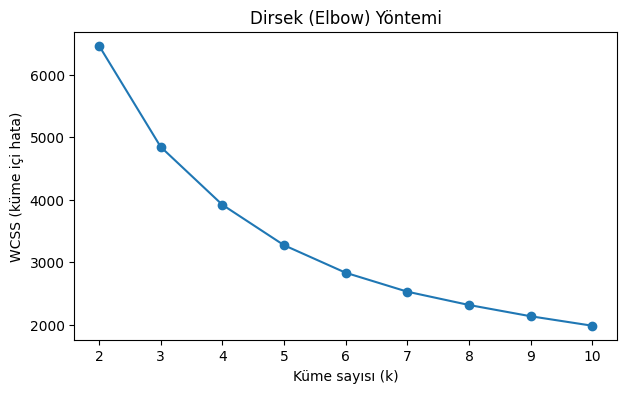

In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    wcss.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(range(2, 11), wcss, marker='o')
plt.xlabel('Küme sayısı (k)')
plt.ylabel('WCSS (küme içi hata)')
plt.title('Dirsek (Elbow) Yöntemi')
plt.show()

In [3]:
from sklearn.metrics import silhouette_score

for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiket = km.fit_predict(X)
    skor = silhouette_score(X, etiket)
    print(f"k={k}  Silhouette={skor:.3f}")

k=2  Silhouette=0.433
k=3  Silhouette=0.338
k=4  Silhouette=0.337
k=5  Silhouette=0.317
k=6  Silhouette=0.314
k=7  Silhouette=0.310
k=8  Silhouette=0.303
k=9  Silhouette=0.281
k=10  Silhouette=0.277


In [4]:
k = 4

km = KMeans(n_clusters=k, random_state=42, n_init=10)
rfm['Kume'] = km.fit_predict(X)

from sklearn.metrics import silhouette_score, davies_bouldin_score
print("Küme büyüklükleri:")
print(rfm['Kume'].value_counts().sort_index())
print("Silhouette:", round(silhouette_score(X, rfm['Kume']), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X, rfm['Kume']), 3))


Küme büyüklükleri:
Kume
0     837
1     714
2    1187
3    1595
Name: count, dtype: int64
Silhouette: 0.337
Davies-Bouldin: 1.012


In [5]:
# özgün ölçekteki tabloyu da al, kümelerin gerçek R/F/M medyanını gör
url2 = "https://raw.githubusercontent.com/Ahmettufan3310/74-musteri-segmentasyonu-rfm/main/data/rfm_ozgun.csv"
rfm_ozgun = pd.read_csv(url2)
rfm_ozgun['Kume'] = rfm['Kume']

profil = rfm_ozgun.groupby('Kume')[['Recency', 'Frequency', 'Monetary']].median().round(1)
profil['Musteri_Sayisi'] = rfm_ozgun['Kume'].value_counts().sort_index()
print(profil)

      Recency  Frequency  Monetary  Musteri_Sayisi
Kume                                              
0        18.0        2.0     450.3             837
1         8.0       10.0    3623.5             714
2        54.0        4.0    1320.2            1187
3       179.0        1.0     292.5            1595


In [6]:
rfm_ozgun.to_csv('kume_sonuclari.csv', index=False)
print("Kaydedildi")

Kaydedildi
